In [1]:

from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = next(iter(uploaded))

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("/content/carebridge_data")

print("Datasets extracted successfully!")
print(os.listdir("/content/carebridge_data"))


Saving CareBridge_Datasets.zip to CareBridge_Datasets.zip
Datasets extracted successfully!
['doctors.csv', 'reminders.csv', 'appointments.csv', 'patients.csv', 'calendar.csv']


Load the datasets

In [2]:

import pandas as pd
import numpy as np
import os

# Dataset folder
data_path = "/content/carebridge_data"

# Load all CSV files
appointments = pd.read_csv(f"{data_path}/appointments.csv")
patients = pd.read_csv(f"{data_path}/patients.csv")
doctors = pd.read_csv(f"{data_path}/doctors.csv")
reminders = pd.read_csv(f"{data_path}/reminders.csv")
calendar = pd.read_csv(f"{data_path}/calendar.csv")

print("All datasets loaded successfully!")

print("\nAppointments:", appointments.shape)
print("Patients:", patients.shape)
print("Doctors:", doctors.shape)
print("Reminders:", reminders.shape)
print("Calendar:", calendar.shape)


All datasets loaded successfully!

Appointments: (3224, 9)
Patients: (650, 5)
Doctors: (28, 5)
Reminders: (3212, 6)
Calendar: (365, 5)


Understand the data

In [3]:

datasets = {
    "Appointments": appointments,
    "Patients": patients,
    "Doctors": doctors,
    "Reminders": reminders,
    "Calendar": calendar
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name.upper())
    print("=" * 50)
    display(df.head())



APPOINTMENTS


,appointment_id,patient_id,doctor_id,appointment_date,booking_date,department,status,waiting_days,appointment_time
0,A00001,P0589,D014,2025-09-13,2025-08-08,Dermatology,Attended,36,09:00
1,A00002,P0572,D025,2025-03-30,2025-02-19,Orthopedics,Attended,39,14:00
2,A00003,P0501,D023,2025-06-01,2025-05-07,Pediatrics,No-show,25,09:00
3,A00004,P0070,D011,2025-09-21,2025-09-19,ENT,No-show,2,09:00
4,A00005,P0319,D008,2025-12-16,2025-10-22,General Medicine,Attended,55,13:30



PATIENTS


,patient_id,age_group,locality,previous_visits,previous_attendance_rate
0,P0001,45-59,Urban,3,0.86
1,P0002,30-44,Rural,4,0.88
2,P0003,60+,Suburban,4,0.80
3,P0004,45-59,Urban,1,0.95
4,P0005,0-17,Rural,1,0.38



DOCTORS


,doctor_id,specialty,department,clinic_schedule,appointments_per_day_capacity
0,D001,ENT Specialist,ENT,Mon-Sat AM,20
1,D002,Pediatrician,Pediatrics,Mon-Sat AM,15
2,D003,Orthopedic Surgeon,Orthopedics,Tue-Sat PM,12
3,D004,Ophthalmologist,Ophthalmology,Mon-Fri PM,18
4,D005,General Physician,General Medicine,Mon-Fri AM,12



REMINDERS


,reminder_id,appointment_id,reminder_type,sent_status,response,sent_date
0,R00001,A00001,SMS,Yes,Confirmed,2025-09-10
1,R00002,A00002,SMS,Yes,No Response,2025-03-29
2,R00003,A00003,SMS,Yes,Confirmed,2025-05-31
3,R00004,A00004,SMS,Yes,No Response,2025-09-20
4,R00005,A00005,Phone Call,Yes,Confirmed,2025-12-14



CALENDAR


,date,weekday,is_weekend,is_holiday,season
0,2025-01-01,Wednesday,False,True,Winter
1,2025-01-02,Thursday,False,False,Winter
2,2025-01-03,Friday,False,False,Winter
3,2025-01-04,Saturday,True,False,Winter
4,2025-01-05,Sunday,True,False,Winter


Check data types, missing values and duplicates

In [4]:

for name, df in datasets.items():
    print(f"\n--- {name} ---")

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nStatistical summary:")
    display(df.describe(include="all").T)



--- Appointments ---

Data types:
appointment_id      object
patient_id          object
doctor_id           object
appointment_date    object
booking_date        object
department          object
status              object
waiting_days         int64
appointment_time    object
dtype: object

Missing values:
appointment_id       0
patient_id           0
doctor_id            0
appointment_date     0
booking_date         0
department           0
status              38
waiting_days         0
appointment_time     0
dtype: int64

Duplicate rows: 22

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
appointment_id,3224,3200,A01237,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_id,3224,649,P0583,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
doctor_id,3224,28,D015,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointment_date,3224,365,2025-09-14,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_date,3224,412,2025-10-06,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,3224,16,Pediatrics,679,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,3186,3,Attended,1618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
waiting_days,3224.0,NaN,NaN,NaN,29.826303,21.686643,-9.0,13.75,29.0,44.0,380.0
appointment_time,3224,8,11:00,421,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Patients ---

Data types:
patient_id                   object
age_group                    object
locality                     object
previous_visits               int64
previous_attendance_rate    float64
dtype: object

Missing values:
patient_id                  0
age_group                   0
locality                    0
previous_visits             0
previous_attendance_rate    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,650,650,P0650,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,650,5,30-44,161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
locality,650,3,Urban,329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
previous_visits,650.0,NaN,NaN,NaN,3.5,1.908742,0.0,2.0,3.0,5.0,12.0
previous_attendance_rate,650.0,NaN,NaN,NaN,0.797877,0.117298,0.35,0.7225,0.81,0.89,0.99



--- Doctors ---

Data types:
doctor_id                        object
specialty                        object
department                       object
clinic_schedule                  object
appointments_per_day_capacity     int64
dtype: object

Missing values:
doctor_id                        0
specialty                        0
department                       0
clinic_schedule                  0
appointments_per_day_capacity    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
doctor_id,28,28,D001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
specialty,28,8,Pediatrician,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,28,8,Pediatrics,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clinic_schedule,28,4,Mon-Sat AM,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
appointments_per_day_capacity,28.0,NaN,NaN,NaN,16.0,2.931312,12.0,14.25,15.0,18.0,20.0



--- Reminders ---

Data types:
reminder_id       object
appointment_id    object
reminder_type     object
sent_status       object
response          object
sent_date         object
dtype: object

Missing values:
reminder_id         0
appointment_id      0
reminder_type     668
sent_status        95
response           65
sent_date         914
dtype: int64

Duplicate rows: 12

Statistical summary:


,count,unique,top,freq
reminder_id,3212,3200,R00718,2
appointment_id,3212,3200,A00718,2
reminder_type,2544,3,SMS,1508
sent_status,3117,3,Yes,2231
response,3147,4,No Response,1599
sent_date,2298,365,2025-06-07,13



--- Calendar ---

Data types:
date          object
weekday       object
is_weekend      bool
is_holiday      bool
season        object
dtype: object

Missing values:
date          0
weekday       0
is_weekend    0
is_holiday    0
season        0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq
date,365,365,2025-12-31,1
weekday,365,7,Wednesday,53
is_weekend,365,2,False,261
is_holiday,365,2,False,355
season,365,4,Summer,92


Clean appointment data

In [5]:

# Work on copies so the original data remains available
appointments_clean = appointments.copy()
patients_clean = patients.copy()
doctors_clean = doctors.copy()
reminders_clean = reminders.copy()
calendar_clean = calendar.copy()

# 1. Convert dates into proper datetime format
for col in ["appointment_date", "booking_date"]:
    appointments_clean[col] = pd.to_datetime(
        appointments_clean[col], errors="coerce"
    )

calendar_clean["date"] = pd.to_datetime(
    calendar_clean["date"], errors="coerce"
)

reminders_clean["sent_date"] = pd.to_datetime(
    reminders_clean["sent_date"], errors="coerce"
)

# 2. Standardize department names
def clean_department(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    mapping = {
        "cardiology": "Cardiology",
        "dermatology": "Dermatology",
        "general med": "General Medicine",
        "general medicine": "General Medicine",
        "orthopaedics": "Orthopedics",
        "orthopedics": "Orthopedics",
        "pediatric": "Pediatrics",
        "pediatrics": "Pediatrics",
        "eye care": "Ophthalmology",
        "ophthalmology": "Ophthalmology",
        "e.n.t.": "ENT",
        "ent": "ENT",
        "neuro": "Neurology",
        "neurology": "Neurology"
    }

    return mapping.get(value, value.title())

appointments_clean["department"] = (
    appointments_clean["department"].apply(clean_department)
)
doctors_clean["department"] = (
    doctors_clean["department"].apply(clean_department)
)

# 3. Remove exact duplicate rows
appointments_clean = appointments_clean.drop_duplicates()

# 4. Remove duplicate booking IDs, keeping the first record
appointments_clean = appointments_clean.drop_duplicates(
    subset=["appointment_id"], keep="first"
)

# 5. Recalculate waiting days from the dates
appointments_clean["waiting_days"] = (
    appointments_clean["appointment_date"]
    - appointments_clean["booking_date"]
).dt.days

# 6. Mark invalid waiting days as missing
invalid_wait = (
    appointments_clean["waiting_days"].isna()
    | (appointments_clean["waiting_days"] < 0)
    | (appointments_clean["waiting_days"] > 120)
)

appointments_clean.loc[invalid_wait, "waiting_days"] = np.nan

# 7. Standardize appointment status
appointments_clean["status"] = (
    appointments_clean["status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

status_mapping = {
    "attended": "Attended",
    "no-show": "No-show",
    "cancelled": "Cancelled"
}

appointments_clean["status"] = (
    appointments_clean["status"].map(status_mapping)
)

print("Appointment cleaning completed!")
print("Remaining rows:", len(appointments_clean))
print("\nMissing values:")
print(appointments_clean.isnull().sum())


Appointment cleaning completed!
Remaining rows: 3200

Missing values:
appointment_id       0
patient_id           0
doctor_id            0
appointment_date     0
booking_date         0
department           0
status              38
waiting_days         0
appointment_time     0
dtype: int64


Clean patients, doctors and reminders

In [6]:

# Remove duplicate patient and doctor IDs
patients_clean = patients_clean.drop_duplicates(
    subset=["patient_id"], keep="first"
)

doctors_clean = doctors_clean.drop_duplicates(
    subset=["doctor_id"], keep="first"
)

# Standardize reminder text
for col in ["reminder_type", "sent_status", "response"]:
    reminders_clean[col] = (
        reminders_clean[col]
        .astype("string")
        .str.strip()
    )

# Remove exact duplicate reminder records
reminders_clean = reminders_clean.drop_duplicates()

# One reminder record per appointment for this dataset.
# Keep the first record and report duplicates before discarding.
print("Duplicate reminder appointment IDs:",
      reminders_clean["appointment_id"].duplicated().sum())

reminders_clean = reminders_clean.drop_duplicates(
    subset=["appointment_id"], keep="first"
)

# Inspect missing reminder details; preserve unknown values
print("\nReminder missing values:")
print(reminders_clean.isnull().sum())

print("\nPatients shape:", patients_clean.shape)
print("Doctors shape:", doctors_clean.shape)
print("Reminders shape:", reminders_clean.shape)


Duplicate reminder appointment IDs: 0

Reminder missing values:
reminder_id         0
appointment_id      0
reminder_type     665
sent_status        95
response           65
sent_date         911
dtype: int64

Patients shape: (650, 5)
Doctors shape: (28, 5)
Reminders shape: (3200, 6)


Check the cleaned datasets


In [7]:

print("CLEANING SUMMARY")
print("-" * 40)

print("Appointments:", appointments_clean.shape)
print("Patients:", patients_clean.shape)
print("Doctors:", doctors_clean.shape)
print("Reminders:", reminders_clean.shape)
print("Calendar:", calendar_clean.shape)

print("\nRemaining duplicate appointment IDs:",
      appointments_clean["appointment_id"].duplicated().sum())

print("\nDepartment names:")
print(sorted(appointments_clean["department"].dropna().unique()))

print("\nAppointment statuses:")
print(appointments_clean["status"].value_counts(dropna=False))

print("\nWaiting days summary:")
display(appointments_clean["waiting_days"].describe())


CLEANING SUMMARY
----------------------------------------
Appointments: (3200, 9)
Patients: (650, 5)
Doctors: (28, 5)
Reminders: (3200, 6)
Calendar: (365, 5)

Remaining duplicate appointment IDs: 0

Department names:
['Cardiology', 'Dermatology', 'ENT', 'General Medicine', 'Neurology', 'Ophthalmology', 'Orthopedics', 'Pediatrics']

Appointment statuses:
status
Attended     1607
No-show      1194
Cancelled     361
NaN            38
Name: count, dtype: int64

Waiting days summary:


,waiting_days
count,3200.000000
mean,29.329687
std,17.743643
min,0.000000
25%,14.000000
50%,29.000000
75%,44.000000
max,60.000000


Save your cleaned datasets

In [8]:

from pathlib import Path

clean_dir = Path("/content/carebridge_cleaned")
clean_dir.mkdir(exist_ok=True)

cleaned_data = {
    "appointments_clean.csv": appointments_clean,
    "patients_clean.csv": patients_clean,
    "doctors_clean.csv": doctors_clean,
    "reminders_clean.csv": reminders_clean,
    "calendar_clean.csv": calendar_clean
}

for filename, df in cleaned_data.items():
    df.to_csv(clean_dir / filename, index=False)

print("All cleaned CSV files saved to:", clean_dir)


All cleaned CSV files saved to: /content/carebridge_cleaned


Merge all five datasets

In [9]:
# Merge appointments with patient information
analysis_df = appointments_clean.merge(
    patients_clean, on="patient_id", how="left"
)

# Merge doctor information
doctor_details = doctors_clean.drop(
    columns=["department"], errors="ignore"
)

analysis_df = analysis_df.merge(
    doctor_details, on="doctor_id", how="left"
)

# Merge reminder information
analysis_df = analysis_df.merge(
    reminders_clean[
        ["appointment_id", "reminder_type",
         "sent_status", "response", "sent_date"]
    ],
    on="appointment_id",
    how="left"
)

# Merge calendar information
calendar_details = calendar_clean.rename(
    columns={"date": "appointment_date"}
)

analysis_df = analysis_df.merge(
    calendar_details,
    on="appointment_date",
    how="left"
)

print("Merged dataset shape:", analysis_df.shape)
display(analysis_df.head())

Merged dataset shape: (3200, 24)


,appointment_id,patient_id,doctor_id,appointment_date,booking_date,department,status,waiting_days,appointment_time,age_group,...,clinic_schedule,appointments_per_day_capacity,reminder_type,sent_status,response,sent_date,weekday,is_weekend,is_holiday,season
0,A00001,P0589,D014,2025-09-13,2025-08-08,Dermatology,Attended,36.0,09:00,18-29,...,Tue-Sat PM,15,SMS,Yes,Confirmed,2025-09-10,Saturday,True,False,Autumn
1,A00002,P0572,D025,2025-03-30,2025-02-19,Orthopedics,Attended,39.0,14:00,60+,...,Mon-Fri AM,12,SMS,Yes,No Response,2025-03-29,Sunday,True,False,Summer
2,A00003,P0501,D023,2025-06-01,2025-05-07,Pediatrics,No-show,25.0,09:00,45-59,...,Mon-Fri PM,18,SMS,Yes,Confirmed,2025-05-31,Sunday,True,False,Monsoon
3,A00004,P0070,D011,2025-09-21,2025-09-19,ENT,No-show,2.0,09:00,30-44,...,Tue-Sat PM,12,SMS,Yes,No Response,2025-09-20,Sunday,True,False,Autumn
4,A00005,P0319,D008,2025-12-16,2025-10-22,General Medicine,Attended,55.0,13:30,18-29,...,Tue-Sat PM,18,Phone Call,Yes,Confirmed,2025-12-14,Tuesday,False,False,Winter


Prepare the analysis data

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Colorful graph theme
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15

# Keep records with a known appointment status
eda_df = analysis_df[
    analysis_df["status"].isin(["Attended", "No-show", "Cancelled"])
].copy()

# No-show indicator: exclude cancellations from attendance comparisons
eda_df["no_show"] = (eda_df["status"] == "No-show").astype(int)

print("Records available for EDA:", len(eda_df))
print("\nAppointment status counts:")
print(eda_df["status"].value_counts())



Records available for EDA: 3162

Appointment status counts:
status
Attended     1607
No-show      1194
Cancelled     361
Name: count, dtype: int64


Graph 1 — Which departments have more missed visits?

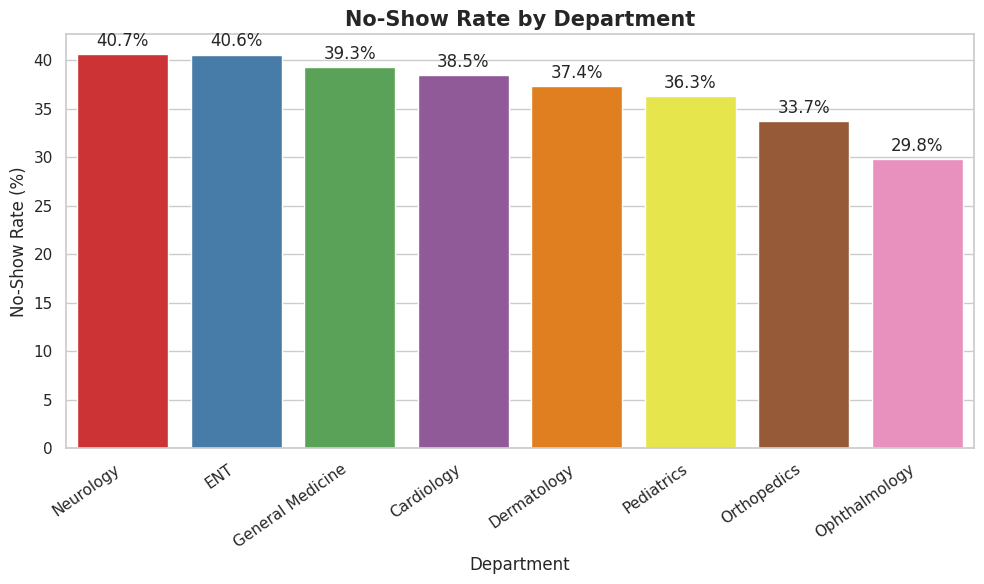

,Total_Appointments,No_Shows,No_Show_Rate
department,,,
Neurology,332,135,40.662651
ENT,554,225,40.613718
General Medicine,336,132,39.285714
Cardiology,470,181,38.510638
Dermatology,329,123,37.386018
Pediatrics,686,249,36.297376
Orthopedics,341,115,33.724340
Ophthalmology,114,34,29.824561


In [11]:

dept_rate = (
    eda_df.groupby("department")
    .agg(
        Total_Appointments=("appointment_id", "count"),
        No_Shows=("no_show", "sum")
    )
)

dept_rate["No_Show_Rate"] = (
    dept_rate["No_Shows"] / dept_rate["Total_Appointments"] * 100
)

dept_rate = dept_rate.sort_values("No_Show_Rate", ascending=False)

ax = sns.barplot(
    data=dept_rate.reset_index(),
    x="department",
    y="No_Show_Rate",
    hue="department",
    palette="Set1",
    legend=False
)

ax.set_title("No-Show Rate by Department")
ax.set_xlabel("Department")
ax.set_ylabel("No-Show Rate (%)")
plt.xticks(rotation=35, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

display(dept_rate)


Graph 2 — Does waiting time affect attendance?

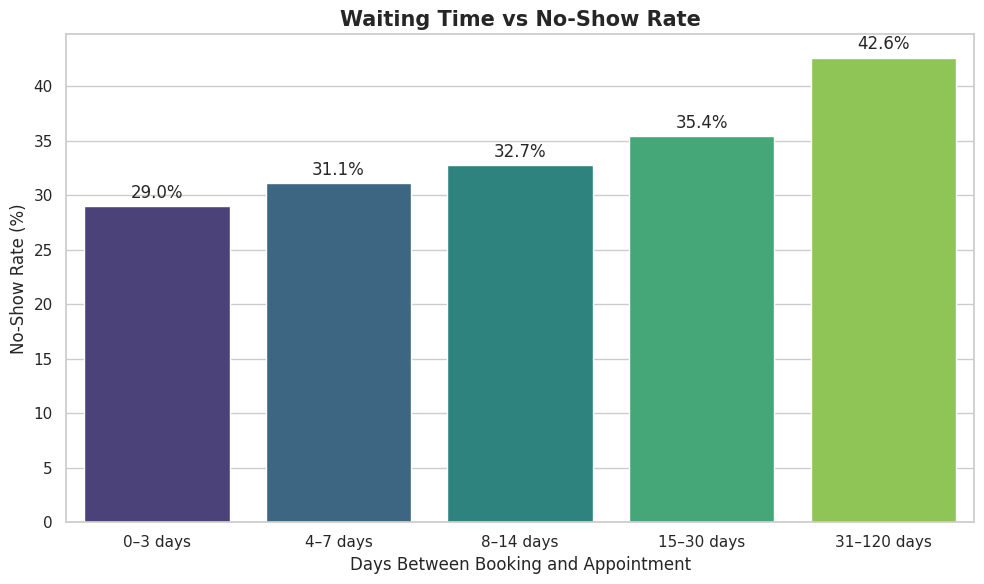

,Total,No_Shows,No_Show_Rate
Waiting Group,,,
0–3 days,238,69,28.991597
4–7 days,209,65,31.100478
8–14 days,388,127,32.731959
15–30 days,811,287,35.388409
31–120 days,1516,646,42.612137


In [12]:

wait_df = eda_df.dropna(subset=["waiting_days"]).copy()

wait_df["Waiting Group"] = pd.cut(
    wait_df["waiting_days"],
    bins=[-1, 3, 7, 14, 30, 120],
    labels=["0–3 days", "4–7 days", "8–14 days",
            "15–30 days", "31–120 days"]
)

wait_summary = (
    wait_df.groupby("Waiting Group", observed=False)
    .agg(
        Total=("no_show", "count"),
        No_Shows=("no_show", "sum"),
        No_Show_Rate=("no_show", "mean")
    )
)

wait_summary["No_Show_Rate"] *= 100

ax = sns.barplot(
    x=wait_summary.index.astype(str),
    y=wait_summary["No_Show_Rate"],
    hue=wait_summary.index.astype(str),
    palette="viridis",
    legend=False
)

ax.set_title("Waiting Time vs No-Show Rate")
ax.set_xlabel("Days Between Booking and Appointment")
ax.set_ylabel("No-Show Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

display(wait_summary)


Graph 3 — Which weekdays have higher no-show rates?

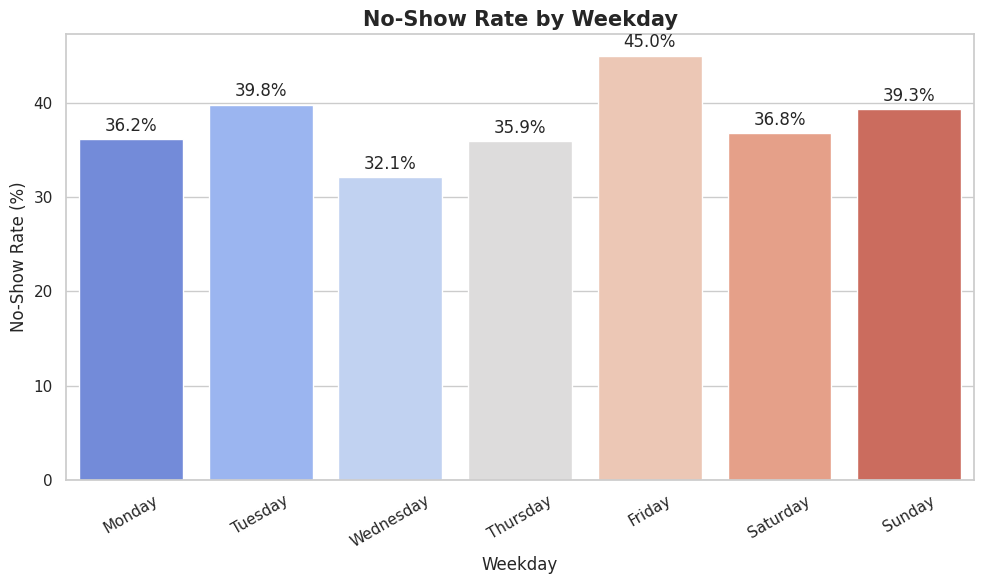

In [13]:

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_df = eda_df.dropna(subset=["weekday"]).copy()

weekday_summary = (
    weekday_df.groupby("weekday")
    .agg(
        Total=("no_show", "count"),
        No_Shows=("no_show", "sum"),
        No_Show_Rate=("no_show", "mean")
    )
)

weekday_summary["No_Show_Rate"] *= 100
weekday_summary = weekday_summary.reindex(weekday_order).dropna()

ax = sns.barplot(
    x=weekday_summary.index,
    y=weekday_summary["No_Show_Rate"],
    hue=weekday_summary.index,
    palette="coolwarm",
    legend=False
)

ax.set_title("No-Show Rate by Weekday")
ax.set_xlabel("Weekday")
ax.set_ylabel("No-Show Rate (%)")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


Graph 4 — Do reminders improve attendance?

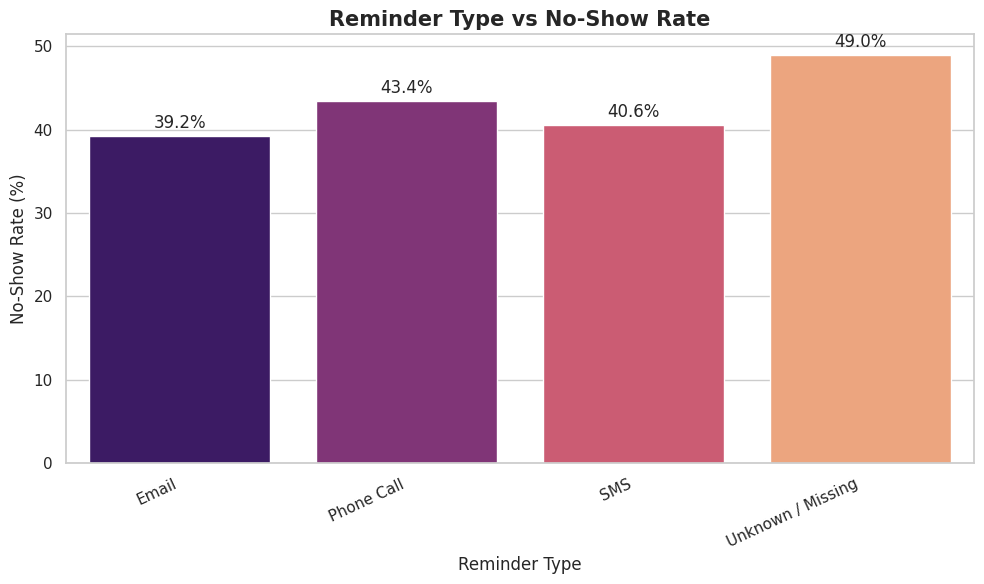

,Total,No_Shows,No_Show_Rate
Reminder Group,,,
Email,395,155,39.240506
Phone Call,507,220,43.392505
SMS,1319,535,40.561031
Unknown / Missing,580,284,48.965517


In [14]:

reminder_df = eda_df[
    eda_df["status"].isin(["Attended", "No-show"])
].copy()

reminder_df["Reminder Group"] = reminder_df["reminder_type"].fillna(
    "Unknown / Missing"
)

reminder_summary = (
    reminder_df.groupby("Reminder Group")
    .agg(
        Total=("no_show", "count"),
        No_Shows=("no_show", "sum"),
        No_Show_Rate=("no_show", "mean")
    )
)

reminder_summary["No_Show_Rate"] *= 100

ax = sns.barplot(
    data=reminder_summary.reset_index(),
    x="Reminder Group",
    y="No_Show_Rate",
    hue="Reminder Group",
    palette="magma",
    legend=False
)

ax.set_title("Reminder Type vs No-Show Rate")
ax.set_xlabel("Reminder Type")
ax.set_ylabel("No-Show Rate (%)")
plt.xticks(rotation=25, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

display(reminder_summary)


Graph 5 — Does previous attendance matter?

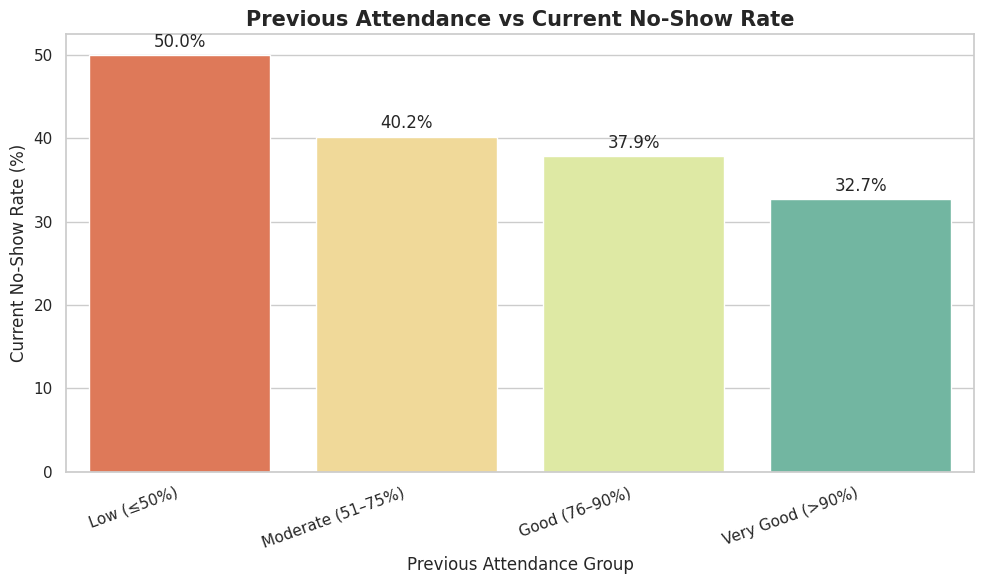

In [15]:

history_df = eda_df.dropna(
    subset=["previous_attendance_rate"]
).copy()

history_df["Previous Attendance Group"] = pd.cut(
    history_df["previous_attendance_rate"],
    bins=[0, 0.50, 0.75, 0.90, 1.01],
    labels=["Low (≤50%)", "Moderate (51–75%)",
            "Good (76–90%)", "Very Good (>90%)"],
    include_lowest=True
)

history_summary = (
    history_df.groupby("Previous Attendance Group", observed=False)
    ["no_show"].mean() * 100
)

ax = sns.barplot(
    x=history_summary.index.astype(str),
    y=history_summary.values,
    hue=history_summary.index.astype(str),
    palette="Spectral",
    legend=False
)

ax.set_title("Previous Attendance vs Current No-Show Rate")
ax.set_xlabel("Previous Attendance Group")
ax.set_ylabel("Current No-Show Rate (%)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


Graph 6 — Which patient groups need scheduling support?

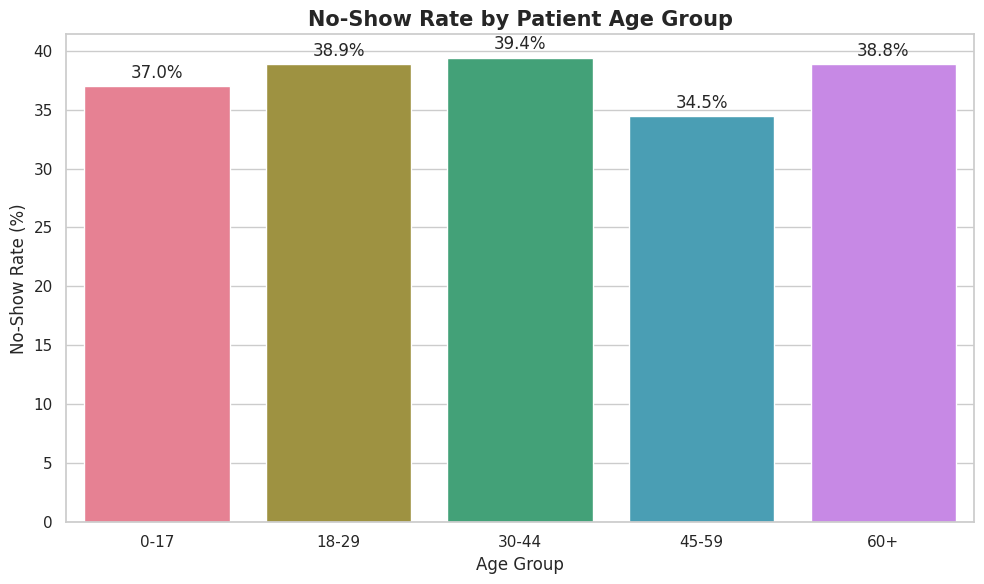

No-show rates by locality:


,No-Show Rate (%)
locality,
Rural,41.64
Suburban,37.00
Urban,36.74


In [16]:

patient_summary = (
    eda_df.groupby("age_group", dropna=False)
    .agg(
        Total=("no_show", "count"),
        No_Shows=("no_show", "sum"),
        No_Show_Rate=("no_show", "mean")
    )
)

patient_summary["No_Show_Rate"] *= 100

ax = sns.barplot(
    x=patient_summary.index.astype(str),
    y=patient_summary["No_Show_Rate"],
    hue=patient_summary.index.astype(str),
    palette="husl",
    legend=False
)

ax.set_title("No-Show Rate by Patient Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("No-Show Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

print("No-show rates by locality:")
display(
    eda_df.groupby("locality", dropna=False)
    ["no_show"].mean().mul(100).round(2)
    .sort_values(ascending=False)
    .rename("No-Show Rate (%)")
)


Create new features

In [17]:

# Create a separate dataset for feature engineering
features_df = analysis_df.copy()

# 1. Convert date columns into datetime
features_df["appointment_date"] = pd.to_datetime(
    features_df["appointment_date"], errors="coerce"
)
features_df["booking_date"] = pd.to_datetime(
    features_df["booking_date"], errors="coerce"
)

# 2. Waiting days: calculate from the actual dates
features_df["waiting_days"] = (
    features_df["appointment_date"] -
    features_df["booking_date"]
).dt.days

# Mark invalid waiting times as missing
features_df.loc[
    (features_df["waiting_days"] < 0) |
    (features_df["waiting_days"] > 120),
    "waiting_days"
] = np.nan

# 3. Appointment month
features_df["appointment_month"] = (
    features_df["appointment_date"].dt.month
)

# 4. Appointment day of month
features_df["appointment_day"] = (
    features_df["appointment_date"].dt.day
)

# 5. Weekend indicator
features_df["is_weekend"] = (
    features_df["appointment_date"].dt.dayofweek >= 5
).astype(int)

# 6. Booking lead-time category
features_df["waiting_category"] = pd.cut(
    features_df["waiting_days"],
    bins=[-1, 3, 7, 14, 30, 120],
    labels=[
        "Short", "Moderate", "Medium",
        "Long", "Very Long"
    ]
)

# 7. Previous attendance category
features_df["attendance_history_group"] = pd.cut(
    features_df["previous_attendance_rate"],
    bins=[0, 0.50, 0.75, 0.90, 1.0],
    labels=["Low", "Moderate", "Good", "Very Good"],
    include_lowest=True
)

# 8. Create target variable
features_df["no_show"] = np.where(
    features_df["status"].eq("No-show"), 1,
    np.where(features_df["status"].eq("Attended"), 0, np.nan)
)

print("Feature engineering completed!")
display(features_df.head())


Feature engineering completed!


,appointment_id,patient_id,doctor_id,appointment_date,booking_date,department,status,waiting_days,appointment_time,age_group,...,sent_date,weekday,is_weekend,is_holiday,season,appointment_month,appointment_day,waiting_category,attendance_history_group,no_show
0,A00001,P0589,D014,2025-09-13,2025-08-08,Dermatology,Attended,36.0,09:00,18-29,...,2025-09-10,Saturday,1,False,Autumn,9,13,Very Long,Moderate,0.0
1,A00002,P0572,D025,2025-03-30,2025-02-19,Orthopedics,Attended,39.0,14:00,60+,...,2025-03-29,Sunday,1,False,Summer,3,30,Very Long,Moderate,0.0
2,A00003,P0501,D023,2025-06-01,2025-05-07,Pediatrics,No-show,25.0,09:00,45-59,...,2025-05-31,Sunday,1,False,Monsoon,6,1,Long,Good,1.0
3,A00004,P0070,D011,2025-09-21,2025-09-19,ENT,No-show,2.0,09:00,30-44,...,2025-09-20,Sunday,1,False,Autumn,9,21,Short,Good,1.0
4,A00005,P0319,D008,2025-12-16,2025-10-22,General Medicine,Attended,55.0,13:30,18-29,...,2025-12-14,Tuesday,0,False,Winter,12,16,Very Long,Good,0.0


Encode categorical variables

In [18]:

# Select useful columns for analysis
categorical_columns = [
    "department",
    "age_group",
    "locality",
    "specialty",
    "reminder_type",
    "weekday",
    "season",
    "waiting_category",
    "attendance_history_group"
]

# Keep only columns that exist in the dataset
categorical_columns = [
    col for col in categorical_columns
    if col in features_df.columns
]

# Create encoded copy
encoded_df = pd.get_dummies(
    features_df,
    columns=categorical_columns,
    dtype=int
)

print("Original dataset shape:", features_df.shape)
print("Encoded dataset shape:", encoded_df.shape)

display(encoded_df.head())


Original dataset shape: (3200, 29)
Encoded dataset shape: (3200, 67)


,appointment_id,patient_id,doctor_id,appointment_date,booking_date,status,waiting_days,appointment_time,previous_visits,previous_attendance_rate,...,season_Winter,waiting_category_Short,waiting_category_Moderate,waiting_category_Medium,waiting_category_Long,waiting_category_Very Long,attendance_history_group_Low,attendance_history_group_Moderate,attendance_history_group_Good,attendance_history_group_Very Good
0,A00001,P0589,D014,2025-09-13,2025-08-08,Attended,36.0,09:00,4,0.56,...,0,0,0,0,0,1,0,1,0,0
1,A00002,P0572,D025,2025-03-30,2025-02-19,Attended,39.0,14:00,2,0.63,...,0,0,0,0,0,1,0,1,0,0
2,A00003,P0501,D023,2025-06-01,2025-05-07,No-show,25.0,09:00,5,0.78,...,0,0,0,0,1,0,0,0,1,0
3,A00004,P0070,D011,2025-09-21,2025-09-19,No-show,2.0,09:00,3,0.79,...,0,1,0,0,0,0,0,0,1,0
4,A00005,P0319,D008,2025-12-16,2025-10-22,Attended,55.0,13:30,1,0.84,...,1,0,0,0,0,1,0,0,1,0


Select important features

In [19]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Use only attended and no-show appointments
model_df = encoded_df[
    encoded_df["no_show"].notna()
].copy()

# Remove identifiers, raw dates, target, and status
exclude_columns = [
    "appointment_id", "patient_id", "doctor_id",
    "appointment_date", "booking_date", "sent_date",
    "status", "no_show", "reminder_id",
    "response"
]

X = model_df.drop(
    columns=exclude_columns,
    errors="ignore"
)

# Convert any remaining text columns to numeric encoding
X = pd.get_dummies(X, dtype=int)

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

y = model_df["no_show"].astype(int)

# Remove columns with no usable values
X = X.dropna(axis=1, how="all")

# Remove rows with missing target only; already filtered above
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Impute missing feature values and fit model
model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
)

model.fit(X_train, y_train)

print("Model training completed!")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Model training completed!
Training rows: 2240
Testing rows: 561


Visualize feature importance

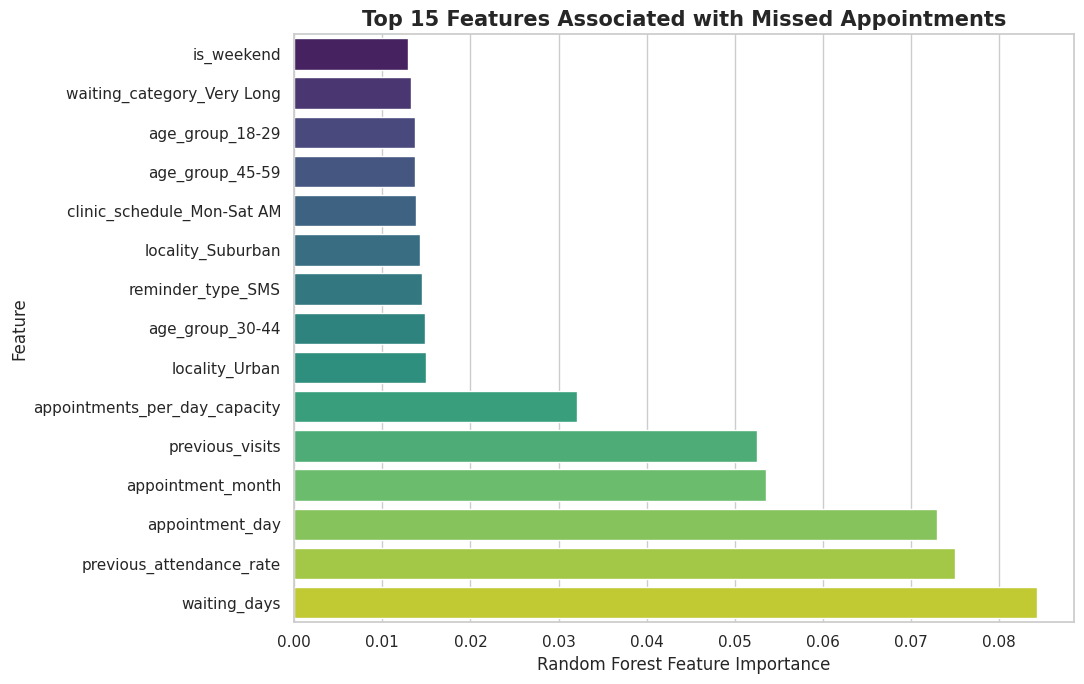

,Feature,Importance
0,waiting_days,0.084272
2,previous_attendance_rate,0.074945
7,appointment_day,0.072973
6,appointment_month,0.053585
1,previous_visits,0.052523
3,appointments_per_day_capacity,0.032034
23,locality_Urban,0.014983
18,age_group_30-44,0.014784
34,reminder_type_SMS,0.014496
22,locality_Suburban,0.014233


In [20]:

importances = model.named_steps[
    "randomforestclassifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top_features = importance_df.head(15).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 15 Features Associated with Missed Appointments")
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importance_df.head(15))


Evaluate the model

Accuracy: 0.594

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.79      0.69       322
           1       0.54      0.33      0.41       239

    accuracy                           0.59       561
   macro avg       0.58      0.56      0.55       561
weighted avg       0.58      0.59      0.57       561



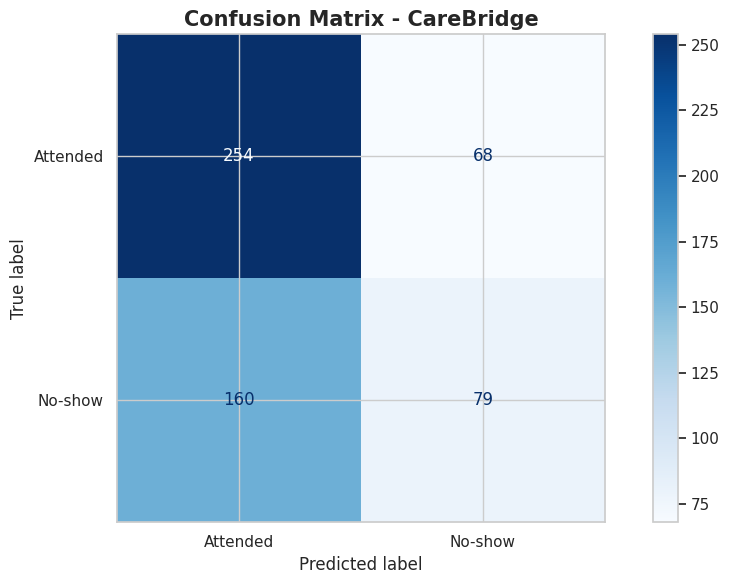

In [21]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

predictions = model.predict(X_test)

print("Accuracy:", round(
    accuracy_score(y_test, predictions), 3
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Attended", "No-show"],
    cmap="Blues"
)

plt.title("Confusion Matrix - CareBridge")
plt.tight_layout()
plt.show()


In [22]:

import os
import zipfile
from google.colab import files

output_dir = "/content/CareBridge_Final_Results"
os.makedirs(output_dir, exist_ok=True)

# Save cleaned datasets
appointments_clean.to_csv(
    f"{output_dir}/appointments_clean.csv", index=False
)
patients_clean.to_csv(
    f"{output_dir}/patients_clean.csv", index=False
)
doctors_clean.to_csv(
    f"{output_dir}/doctors_clean.csv", index=False
)
reminders_clean.to_csv(
    f"{output_dir}/reminders_clean.csv", index=False
)
calendar_clean.to_csv(
    f"{output_dir}/calendar_clean.csv", index=False
)

# Save merged and engineered data
analysis_df.to_csv(
    f"{output_dir}/merged_analysis.csv", index=False
)
features_df.to_csv(
    f"{output_dir}/engineered_features.csv", index=False
)

# Save feature selection results
importance_df.to_csv(
    f"{output_dir}/feature_importance.csv", index=False
)

# Package the results
zip_path = "/content/CareBridge_Final_Results.zip"

with zipfile.ZipFile(zip_path, "w") as z:
    for filename in os.listdir(output_dir):
        z.write(
            os.path.join(output_dir, filename),
            arcname=filename
        )

print("Final results ZIP created successfully!")
files.download(zip_path)


Final results ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>